In [1]:
"""
Another Supervised learning model

Logistic regression is used mainly for classification, where the answer is a category rather than a continuous number.
For example:
- Will the customer buy? Yes or No
- Is the email spam? Spam or not spam
- Does the patient have a condition? Positive or negative
Despite the word “regression,” it is a classification algorithm.
"""


'\nAnother Supervised learning model\n\nLogistic regression is used mainly for classification, where the answer is a category rather than a continuous number.\nFor example:\n- Will the customer buy? Yes or No\n- Is the email spam? Spam or not spam\n- Does the patient have a condition? Positive or negative\nDespite the word “regression,” it is a classification algorithm.\n'

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report


In [136]:
data = pd.read_csv("data.csv")

In [137]:
data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [138]:
data.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')

In [139]:
data.drop(columns=["PassengerId","Name","Ticket"], inplace=True)

In [140]:
data.columns

Index(['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Cabin',
       'Embarked'],
      dtype='str')

In [141]:
print(data.info())
# 3 Categorial data, needs encoding 


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    str    
 3   Age       714 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
 7   Cabin     204 non-null    str    
 8   Embarked  889 non-null    str    
dtypes: float64(2), int64(4), str(3)
memory usage: 62.8 KB
None


In [142]:
print(data.describe())


         Survived      Pclass         Age       SibSp       Parch        Fare
count  891.000000  891.000000  714.000000  891.000000  891.000000  891.000000
mean     0.383838    2.308642   29.699118    0.523008    0.381594   32.204208
std      0.486592    0.836071   14.526497    1.102743    0.806057   49.693429
min      0.000000    1.000000    0.420000    0.000000    0.000000    0.000000
25%      0.000000    2.000000   20.125000    0.000000    0.000000    7.910400
50%      0.000000    3.000000   28.000000    0.000000    0.000000   14.454200
75%      1.000000    3.000000   38.000000    1.000000    0.000000   31.000000
max      1.000000    3.000000   80.000000    8.000000    6.000000  512.329200


<Axes: xlabel='Age'>

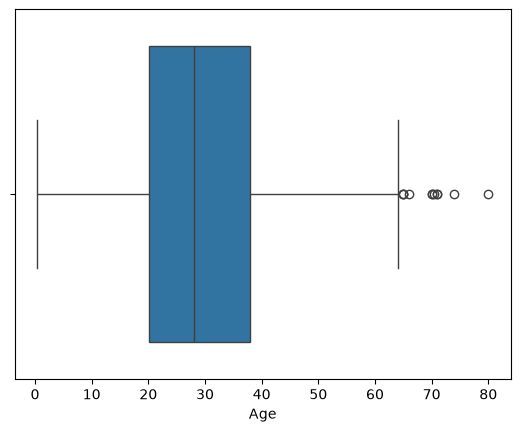

In [143]:
sns.boxplot(data=data, x="Age")

<Axes: xlabel='Fare'>

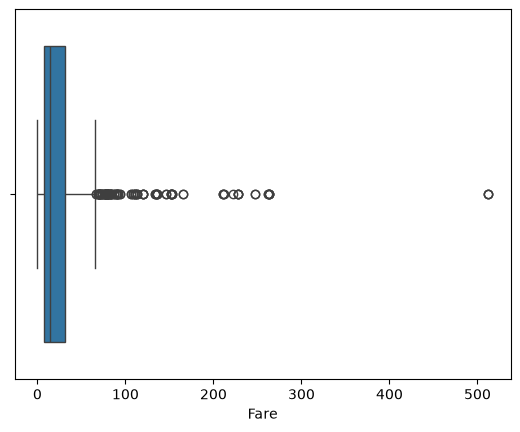

In [144]:
sns.boxplot(data=data, x="Fare")

In [145]:
data.isna().sum()
# we have alot of missing in age and cabin

Survived      0
Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Cabin       687
Embarked      2
dtype: int64

In [146]:
print(len(data))
print(687/len(data)) # 77% missing 
# too much missing in cabin so drop better
data.drop(columns=["Cabin"], inplace=True)

891
0.7710437710437711


In [147]:
data

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S
...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S
887,1,1,female,19.0,0,0,30.0000,S
888,0,3,female,NaN,1,2,23.4500,S
889,1,1,male,26.0,0,0,30.0000,C


In [148]:
# checking out the other values
print(data["Pclass"].value_counts())
print(data["Parch"].value_counts())
print(data.Embarked.value_counts())

Pclass
3    491
1    216
2    184
Name: count, dtype: int64
Parch
0    678
1    118
2     80
5      5
3      5
4      4
6      1
Name: count, dtype: int64
Embarked
S    644
C    168
Q     77
Name: count, dtype: int64


<Axes: xlabel='Embarked', ylabel='count'>

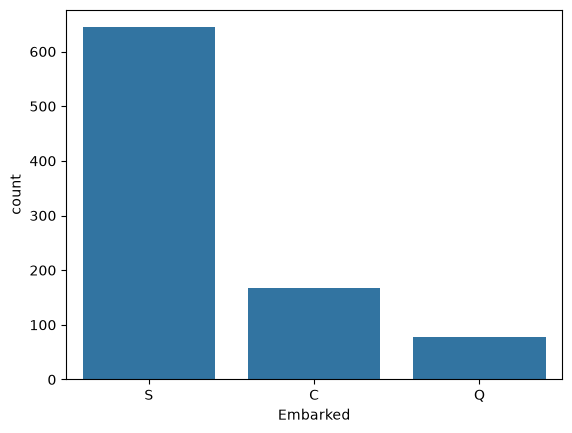

In [149]:
sns.countplot(data=data, x="Embarked")

<Axes: xlabel='Survived', ylabel='count'>

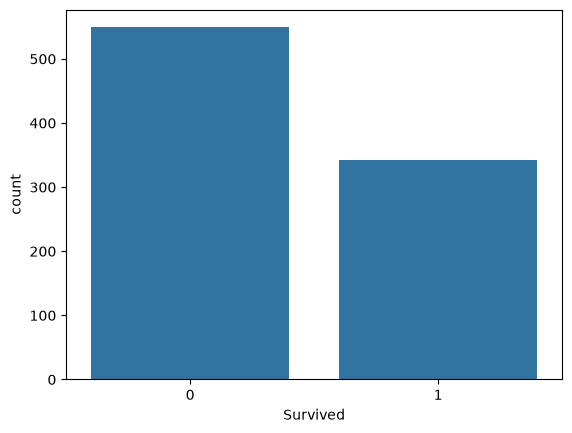

In [150]:
sns.countplot(data=data, x="Survived")

In [151]:
# 1) Feature Selection
# 2) Handling nulls
# 3) Handling outliers
# 4) Splitting data into train and test
# 5) Encoding
# 6) Scaling if needed

In [152]:
data.isna().sum() # handling null

Survived      0
Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Embarked      2
dtype: int64

In [153]:
data["Embarked"] = data["Embarked"].fillna(data["Embarked"].mode().iloc[0])
# fills missing values in the Embarked column with its most common value: 
# iloc[0] selects the most repeated

<Axes: xlabel='Pclass', ylabel='Age'>

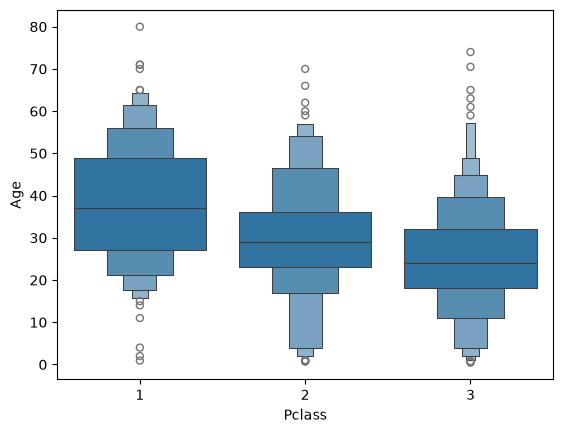

In [154]:
sns.boxenplot(x="Pclass",y="Age", data=data)
# Checking relation to fillin missing data correctly

In [155]:
def impute_age(cols):
    Age = cols["Age"]
    Pclass = cols["Pclass"]
    if pd.isnull(Age):
        if Pclass == 1:
            return 38
        elif Pclass == 2:
            return 30
        elif Pclass == 3:
            return 25
    else:
        return Age
data["Age"] = data[["Age", "Pclass"]].apply(impute_age, axis=1)
# Fills or replaces values in the Age column using the Age and Pclass values from each row
# selects both columns and applies the impute_age function to each row (axis=1) to fill in missing Age values based on the corresponding Pclass.

In [156]:
data.isna().sum()

Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64

In [157]:
# Handling Outliers 
q1 = data["Age"].quantile(0.25)
q3 = data["Age"].quantile(0.75)
iqr= q3 -q1 
lower_bound = q1 - (1.5*iqr)
upper_bound = q3 + (1.5*iqr)

data = data[(data["Age"] >= lower_bound) & (data["Age"] <= upper_bound) ]

In [158]:
q1 = data["Fare"].quantile(0.25)
q3 = data["Fare"].quantile(0.75)
iqr= q3 -q1 
lower_bound = q1 - (1.5*iqr)
upper_bound = q3 + (1.5*iqr)

data = data[(data["Fare"] >= lower_bound) & (data["Fare"] <= upper_bound) ]

<Axes: xlabel='Age'>

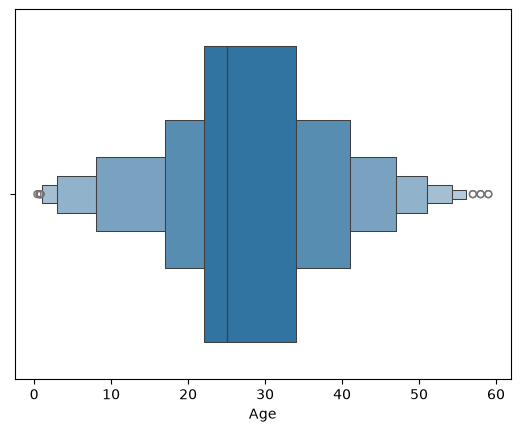

In [159]:
sns.boxenplot(data=data, x="Age")

<Axes: xlabel='Fare'>

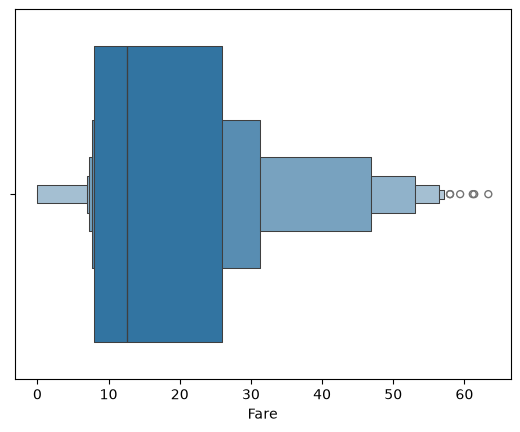

In [160]:
sns.boxenplot(data=data, x="Fare")

In [161]:
data

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S
5,0,3,male,25.0,0,0,8.4583,Q
...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S
887,1,1,female,19.0,0,0,30.0000,S
888,0,3,female,25.0,1,2,23.4500,S
889,1,1,male,26.0,0,0,30.0000,C


In [162]:
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, OneHotEncoder

# OrdinalEncoder converts categorical text values into numbers so a machine-learning model can use them.
# Use OrdinalEncoder when categories have a real order
# Label will just assign numbers, NOT ordered

In [163]:
# 4) Splitting data into train and test
# 5) Encoding
ord1 = OrdinalEncoder()

label1 = LabelEncoder()

In [164]:
features = data.drop(columns="Survived")
target = data["Survived"]

In [165]:
Xtrain, Xtest, ytrain, ytest = train_test_split(features, target, test_size=0.2, random_state=1)

In [166]:
print(Xtrain.shape)
print(Xtest.shape)
print(ytrain.shape)
print(ytest.shape)

(602, 7)
(151, 7)
(602,)
(151,)


In [167]:
Xtrain[["Sex", "Embarked"]] = ord1.fit_transform(Xtrain[["Sex", "Embarked"]])

In [168]:
Xtrain

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
648,3,1.0,25.0,0,0,7.5500,2.0
346,2,0.0,40.0,0,0,13.0000,2.0
105,3,1.0,28.0,0,0,7.8958,2.0
686,3,1.0,14.0,4,1,39.6875,2.0
588,3,1.0,22.0,0,0,8.0500,2.0
...,...,...,...,...,...,...,...
770,3,1.0,24.0,0,0,9.5000,2.0
848,2,1.0,28.0,0,1,33.0000,2.0
82,3,0.0,25.0,0,0,7.7875,1.0
271,3,1.0,25.0,0,0,0.0000,2.0


In [ ]:
# testing , ONLY transform
# We fit only on the training data because fitting means learning information from the data. 
# The test data must remain unseen so it can fairly evaluate the model.
Xtest[["Sex", "Embarked"]] = ord1.transform(Xtest[["Sex", "Embarked"]])

In [170]:
Xtest

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
854,2,0.0,44.0,1,0,26.0000,2.0
531,3,1.0,25.0,0,0,7.2292,0.0
69,3,1.0,26.0,2,0,8.6625,2.0
183,2,1.0,1.0,2,1,39.0000,2.0
461,3,1.0,34.0,0,0,8.0500,2.0
...,...,...,...,...,...,...,...
503,3,0.0,37.0,0,0,9.5875,2.0
350,3,1.0,23.0,0,0,9.2250,2.0
500,3,1.0,17.0,0,0,8.6625,2.0
14,3,0.0,14.0,0,0,7.8542,2.0


In [171]:
logmodel = LogisticRegression()
logmodel.fit(Xtrain, ytrain)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [172]:
ypred = logmodel.predict(Xtest)

In [173]:
print(accuracy_score(ypred, ytest))

0.7615894039735099


In [174]:
print(classification_report(ypred, ytest))

              precision    recall  f1-score   support

           0       0.81      0.81      0.81        96
           1       0.67      0.67      0.67        55

    accuracy                           0.76       151
   macro avg       0.74      0.74      0.74       151
weighted avg       0.76      0.76      0.76       151

